# 10층 · 생성형 AI 실습

프롬프트를 AI에게 보내 받은 파이썬 코드입니다. 위에서부터 셀을 차례로 실행해 보세요.
데이터는 GitHub 저장소에서 바로 불러옵니다.

저장된 결과는 Python 3.13.18 · pandas 3.0.5 · scikit-learn 1.9.1 · NumPy 2.5.3 · matplotlib 3.11.2 로 실행한 것입니다. Colab에서는 라이브러리 버전에 따라 소수점이 조금 다를 수 있습니다.

## 실습 1 · 의료비 데이터 첫인상 — 꼬리가 긴 분포

**프롬프트**

> 보험 의료비 데이터(insurance.csv)를 불러와서
> 의료비(charges)의 평균과 중앙값, 흡연 여부별 평균을 보여 주고
> 의료비 히스토그램을 그려 주세요(그래프 글자는 영어).

행, 열: (1338, 7)
평균: 13270 / 중앙값: 9382
smoker
no      8434.0
yes    32050.0
Name: charges, dtype: float64


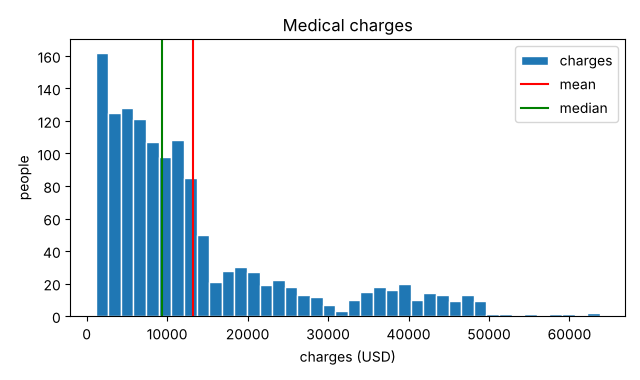

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)
print("행, 열:", df.shape)
print("평균:", round(df["charges"].mean()), "/ 중앙값:", round(df["charges"].median()))
print(df.groupby("smoker")["charges"].mean().round(0))

df["charges"].plot.hist(bins=40, edgecolor="white")
plt.axvline(df["charges"].mean(), color="red", label="mean")
plt.axvline(df["charges"].median(), color="green", label="median")
plt.xlabel("charges (USD)"); plt.ylabel("people"); plt.legend(); plt.title("Medical charges")
plt.show()

**박사의 한 줄 판단** — 평균 13,270달러가 중앙값 9,382달러보다 큽니다 — 아주 비싼 일부가 평균을 끌어올린, 꼬리가 긴 분포예요. 흡연자 평균은 비흡연자의 약 3.8배입니다.

## 실습 2 · 평균만 답하기 vs 부스팅 — 그룹별 오차까지

**프롬프트**

> insurance.csv로 의료비를 맞히는 그래디언트 부스팅을 만들고
> “평균만 답하기”와 MAE를 비교해 주세요.
> 그리고 시험용에서 흡연자·비흡연자·의료비 상위 10% 그룹별 MAE도 보여 주세요.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

df = pd.read_csv("https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv")
X = pd.get_dummies(df.drop(columns="charges"), drop_first=True, dtype=int)
y = df["charges"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

base = np.full(len(y_test), y_train.mean())
gb = GradientBoostingRegressor(random_state=0).fit(X_train, y_train)
pred = gb.predict(X_test)
print("평균만 답하기 MAE:", round(mean_absolute_error(y_test, base)))
print("부스팅 MAE       :", round(mean_absolute_error(y_test, pred)))

groups = {"흡연자": X_test["smoker_yes"] == 1,
          "비흡연자": X_test["smoker_yes"] == 0,
          "상위 10%": y_test >= y_test.quantile(0.9)}
for g, mask in groups.items():
    print(g, "MAE:", round(mean_absolute_error(y_test[mask], pred[mask])), f"({int(mask.sum())}명)")

평균만 답하기 MAE: 9593
부스팅 MAE       : 2453
흡연자 MAE: 2637 (54명)
비흡연자 MAE: 2407 (214명)
상위 10% MAE: 2861 (27명)


**박사의 한 줄 판단** — 부스팅 MAE 2,453달러로 평균만 답하기(9,593달러)보다 약 74% 줄었습니다. 그룹별로는 의료비 상위 10%의 오차가 가장 큽니다. 본문 그래프의 그룹별 숫자와는 다르니, 보고서에는 그룹을 나눈 기준과 설정을 함께 적습니다.